# Unidades 20 y 21: Closures, expresiones regulares y POO

## Unidad 20: Closures y expresiones regulares

### 20.1 Ámbito de las variables (LEGB)

**Problema:** saber qué variable usa Python cuando hay varias con el mismo nombre.

Python busca un nombre en este orden y se detiene en el primero que lo encuentra:

| Letra | Ámbito | Qué contiene |
|---|---|---|
| **L** Local | La función actual | Parámetros y variables creadas en ella |
| **E** Enclosing | Las funciones que la contienen | Variables de la función externa |
| **G** Global | El programa | Nombres creados fuera de funciones |
| **B** Built-in | Python | `len`, `print`, `sum`... |

- **Leer** una variable usa esta búsqueda. **Asignar** dentro de una función crea una variable **local**, salvo que se declare `global`.
- Si el nombre no está en ningún nivel: `NameError`.
- Evita `global`: cualquier parte del programa puede cambiarla y los errores cuestan encontrarlos. Es mejor recibir datos por parámetro y devolver resultados.

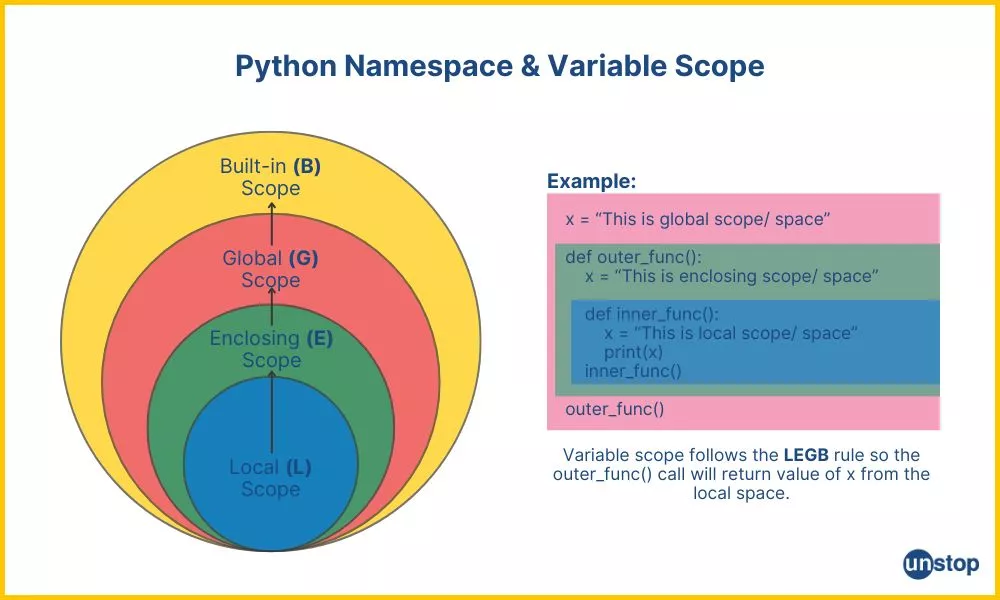

In [ ]:
saludo = "G: global"

def externa():
    despedida = "E: de la externa - modificacion"
    def interna():
        etiqueta = "L: local"
        print(etiqueta)    # se encuentra en L
        print(despedida)   # no está en L, se encuentra en E
        print(saludo)      # no está en L ni E, se encuentra en G
        print(len)         # se encuentra en B
    interna()

externa()

print("-"*20)

# Mismo nombre en distintos ámbitos: gana el más cercano
nombre = "variable global"

def mostrar_nombre():
    nombre = "var local"
    print("dentro:", nombre)

mostrar_nombre()        #1
print("fuera:", nombre) #2

print("-"*20)

# Asignar dentro de una función crea una variable local
contador = 0

def sumar_sin_global():
    contador = contador + 1         # contador ahora es local y aún no tiene valor
    print("contador:", contador)

#sumar_sin_global()

def sumar_con_global():
    global contador              # permite reasignar la variable global
    contador = contador + 1

sumar_con_global()
sumar_con_global()
sumar_con_global()
print("contador 2:", contador)


**Ejercicio 20.1.** Define una función externa con la variable `ciudad = "Panama"` y, dentro, una función interna que imprima `ciudad`. Llama a la interna desde la externa. Después, fuera de las funciones, intenta imprimir `ciudad` con `try` / `except NameError`.
**Resultado esperado:** `Panama` y un mensaje de `NameError`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

### 20.2 Funciones como objetos y funciones anidadas

**Problema:** para entender los closures primero hay que poder pasar y devolver funciones.

- Una función es un **objeto**: se puede guardar en una variable, pasar como argumento y devolver como resultado.
- `funcion` es la función en sí. `funcion()` la **ejecuta** y da su resultado.
- Una **función anidada** se define dentro de otra. Puede **leer** las variables de la externa (nivel E) y no existe fuera de ella.
- Si la externa **devuelve** la interna (sin paréntesis), quien llama recibe una función nueva. Eso lleva a los closures.

In [ ]:
# Funciones como objetos
def sumar(a, b):
    return a + b

operacion = sumar            # sin paréntesis: otro nombre para la misma función
print(operacion(2, 3))
print(sumar)                 # el objeto función
print(sumar(2, 3))           # el resultado de ejecutarla

def triple(numero):
    return numero * 3

def aplicar_dos_veces(funcion, valor):   # una función recibida como argumento
    return funcion(funcion(valor))

print(aplicar_dos_veces(triple, 2))

In [ ]:
# Funciones anidadas
def calcular_total(precio):
    impuesto = 0.07
    def aplicar_impuesto():
        return round(precio * (1 + impuesto), 2)   # lee precio e impuesto (nivel E)
    return aplicar_impuesto()

print(calcular_total(100))

try:
    aplicar_impuesto()       # la interna no existe fuera de la externa
except NameError as error:
    print("NameError:", error)

In [ ]:
# La externa devuelve la interna
def crear_saludador(saludo):
    def saludar(nombre):
        return f"{saludo}, {nombre}"
    return saludar           # se devuelve la función, sin paréntesis

saludar_formal = crear_saludador("Buenos dias")
saludar_informal = crear_saludador("Que onda")
print(saludar_formal("Ana"))
print(saludar_informal("Jose"))

**Ejercicio 20.2.** Escribe `calcular_area_con_unidad(base, altura)` que tenga una función interna `formatear(valor)` que devuelva el texto `<valor> cm2`, y que devuelva el área formateada. Prueba con `4` y `5`.
**Resultado esperado:** `20 cm2`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

### 20.3 Closures

**Problema:** que una función recuerde datos entre llamadas, sin usar variables globales.

- **Variable libre:** variable que la función interna usa pero no define; viene de la externa.
- **Closure:** función interna que usa variables libres y las **recuerda** aunque la función externa ya haya terminado.
- Estructura: (1) una función externa con un parámetro, (2) una función interna que lo usa, (3) la externa **devuelve** la interna.
- Cada closure creado guarda **su propio** valor.

In [ ]:
def crear_multiplicador(factor):          # factor es local de la externa
    def multiplicar(numero):
        return numero * factor            # factor es una variable libre
    return multiplicar                    # se devuelve la función, sin paréntesis

duplicar = crear_multiplicador(2)         # la externa se ejecuta y termina aquí
triplicar = crear_multiplicador(3)

print("x2:", duplicar(10), "| x3:",triplicar(10))        # cada closure recuerda su factor

print('-'*45)

del crear_multiplicador                   # aunque la externa desaparezca...

print("Duplicar_con_eliminacion:", duplicar(21))                       # ...el closure sigue funcionando

**Ejercicio 20.3.** Escribe `crear_sumador(cantidad)` que devuelva una función que sume `cantidad` a su argumento. Crea `sumar_cinco` y `sumar_cien` y llámalas con `10` y `1`.
**Resultado esperado:** `15` y `101`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

def crear_sumador(cantidad):
    def sumador(x):
        return x + cantidad
    return sumador


def sumar_cinco(x):
    return crear_sumador(5)(x)


def sumar_cien(x):
    return crear_sumador(100)(x)


sumar_cinco_resultado = sumar_cinco(10)
sumar_cien_resultado = sumar_cien(1)


print(sumar_cinco_resultado)
print(sumar_cien_resultado)

In [ ]:
def crear_sumador(cantidad):
    def sumador(x):
        return x + cantidad
    return sumador


sumar_cinco = crear_sumador(5)
sumar_cien = crear_sumador(100)


print(sumar_cinco(10))
print(sumar_cien(1))

In [ ]:
def crear_sumador(cantidad):
    def sumar(num):
        return num + cantidad
    return sumar

sumar_dos = crear_sumador(2)
print(sumar_dos(10))

### 20.4 Modificar la variable capturada con `nonlocal`

**Problema:** que un closure pueda **cambiar** la variable que capturó y así guardar un estado (un contador, un total).

- Leer una variable libre funciona sola. **Reasignarla** (`cuenta = cuenta + 1`) crearía una local nueva y daría `UnboundLocalError`.
- `nonlocal nombre` indica que el nombre pertenece a la función externa.

- `global` apunta al programa.

- `nonlocal` apunta a la función que contiene a la actual.

In [29]:
def crear_contador():
    cuenta = 0
    def contar():
        nonlocal cuenta       # la variable es de la función externa
        cuenta += 1
        return cuenta
    return contar

contar_visitas = crear_contador()
print("Contador de Visitas:", contar_visitas(), contar_visitas(), contar_visitas())

otro_contador = crear_contador()          # estado independiente
print("Otro contador:",otro_contador(),"| Contador de visitas:", contar_visitas())

Contador de Visitas: 1 2 3
Otro contador 1 | Contador de visitas: 4


In [28]:
# Sin nonlocal falla
def crear_contador_roto():
    cuenta = 0
    def contar():
        cuenta += 1
        return cuenta
    return contar

try:
    crear_contador_roto()()
except UnboundLocalError as error:
    print("UnboundLocalError:", error)

UnboundLocalError: cannot access local variable 'cuenta' where it is not associated with a value


**Ejercicio 20.4.** Escribe `crear_contador_regresivo(inicio)` cuya función interna use `nonlocal` y devuelva `inicio - 1`, `inicio - 2`... en cada llamada. Créalo con `3` y llámalo tres veces.
**Resultado esperado:** `2`, `1`, `0`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

### 20.5 Expresiones regulares con `re`

**Problema:** buscar y extraer **patrones** de texto (números, palabras, códigos) sin escribir bucles a mano.

Se usa `import re` y los patrones se escriben como cadenas crudas `r"..."` (para que `\` no se interprete como escape).

| Elemento | Significado |
|---|---|
| `re.search(patron, texto)` | **Primera** coincidencia, o `None` si no hay |
| `re.findall(patron, texto)` | **Todas** las coincidencias, en una lista |
| `.group()` / `.span()` | Texto encontrado / posición (inicio, fin) |
| `\d` / `\w` | Un dígito / una letra, dígito o `_` |
| `+` | Una o más repeticiones de lo anterior |
| `[a-z]` | Una letra minúscula |
| `^` / `$` | Inicio / final del texto |

In [38]:
import re

texto = "Mi telefono es 508527-4685296123 y mi codigo es ABCD12A3"

primera = re.search(r"\d+", texto)             # primera coincidencia
print(primera.group(), primera.span())
print("-"*20)
print(re.findall(r"\d+", texto))               # todas las coincidencias
print(re.search(r"xyz", texto))

print(re.findall(r"\w+", "Hola, mundo_2024!"))
print("-"*50)
print(re.findall(r"[a-z]+", "cuaderno 3 Lapicero 5"))
print(re.findall(r"[A-Za-z]+", "cuaderno Lapicero"))
print("-"*50)
print(re.search(r"^Hola", "Hola mundo") is not None)    # empieza con Hola
print(re.search(r"Mundo$", "Hola Mundo") is not None)   # termina con mundo

508527 (15, 21)
--------------------
['508527', '4685296123', '12', '3']
None
['Hola', 'mundo_2024']
--------------------------------------------------
['cuaderno', 'apicero']
['cuaderno', 'Lapicero']
--------------------------------------------------
True
True


**Ejercicio 20.5.** Escribe `es_entero_positivo(texto)` que devuelva `True` si el texto son solo dígitos (usa `r"^\d+$"`). Pruébala con `"2024"`, `"20a4"` y `""`.
**Resultado esperado:** `True`, `False`, `False`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

## Unidad 21: Programación orientada a objetos (POO)

### 21.1 Clases y objetos

**Problema:** mantener juntos los datos de una cosa y lo que se puede hacer con ella.

- **Clase:** el molde.
- **Objeto** (o **instancia**): una pieza concreta creada con ese molde.
- **Atributos:** los datos del objeto.
- **Métodos:** las funciones de la clase que trabajan con el objeto.
- En Python **todo es un objeto**: números, textos, listas, funciones. `type(x)` dice de qué clase es `x` e `isinstance(x, Clase)` pregunta si lo es.

In [39]:
class Perro:
    pass                      # una clase vacía: el molde

mi_perro = Perro()            # un objeto creado con ese molde
mi_perro.nombre = "Rex"       # un atributo del objeto
print(mi_perro.nombre)

print(type(5), type("hola"), type([1]), type(mi_perro))
print(isinstance(mi_perro, Perro))

Rex
<class 'int'> <class 'str'> <class 'list'> <class '__main__.Perro'>
True


### 21.2 El constructor `__init__` y `self`

**Problema:** dar valores iniciales a cada objeto, y que cada método sepa con qué objeto está trabajando.

```python
class NombreClase:
    def __init__(self, parametros):
        self.atributo = parametros      # guarda un dato en el objeto
    def metodo(self):
        ...                             # usa self.atributo
```

- **`__init__`** es el **constructor**: se ejecuta solo al escribir `Persona("Ana", 30)`. Recibe los argumentos y guarda los atributos con `self.atributo = valor`. No crea el objeto (Python ya lo creó): lo **inicializa**.
- **`self`** es **el objeto con el que se está trabajando**. Python lo entrega solo; por eso no se escribe al llamar. `ana.presentarse()` equivale a `Persona.presentarse(ana)`.
- Cada objeto tiene **sus propios** atributos.

In [42]:
class Persona:
    def __init__(self, nombre, edad):
        self.nombre = nombre
        self.edad = edad

    def presentarse(self):
        return f"Soy {self.nombre} y tengo {self.edad} años"

    def cumplir_añios(self):
        self.edad += 1                  # modifica el objeto que llama



ana = Persona("Ana", 30)                # se ejecuta __init__
luis = Persona("Luis", 25)

print(ana.presentarse())
print(luis.presentarse())



print('-'*45)

ana.cumplir_añios()
print(ana.edad, luis.edad)              # solo cambió Ana
luis.cumplir_añios()
luis.cumplir_añios()
print(Persona.presentarse(luis))        # forma equivalente: se pasa el objeto a mano

Soy Ana y tengo 30 años
Soy Luis y tengo 25 años
---------------------------------------------
31 25
Soy Luis y tengo 27 años


**Ejercicio 21.2.** Crea la clase `Rectangulo` con los atributos `ancho` y `alto` y el método `calcular_area()`. Imprime el área de `Rectangulo(4, 5)` y de `Rectangulo(2, 3)`.
**Resultado esperado:** `20` y `6`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

### 21.3 El método `__str__`

**Problema:** al imprimir un objeto sale un texto poco útil.

- `__str__` devuelve el texto legible del objeto. Lo usan `print(objeto)` y `str(objeto)`.
- Es un **método mágico** (o especial): tiene doble guion bajo y Python lo llama automáticamente.

In [43]:
class Libro:
    def __init__(self, titulo, paginas):
        self.titulo = titulo
        self.paginas = paginas

libro = Libro("Python facil", 250)
print(libro)                            # sin __str__: texto poco útil

In [44]:
class LibroLegible:
    def __init__(self, titulo, paginas):
        self.titulo = titulo
        self.paginas = paginas

    def __str__(self):
        return f"{self.titulo} ({self.paginas} paginas)"

libro_legible = LibroLegible("Python facil", 250)
print(libro_legible)                    # print usa __str__

Python facil (250 paginas)


- __init__ le enseña a Python cómo construir el objeto.
- __str__ le enseña cómo mostrarlo en la pantalla".

**Cuándo SÍ debes crearlo:**

- **Para depurar tu código (Debugging):** Si estás desarrollando y necesitas hacer print(objeto) constantemente para ver si los datos se están guardando bien, __str__ te ahorrará mucho tiempo.

- **Clases que representan datos del mundo real:** Si tu clase representa un Usuario, un Producto, un Libro o un Cliente, casi siempre querrás una representación en texto limpia para mostrarla en consolas, interfaces o reportes.

- **Para facilitarle la vida a otros programadores:** Si estás creando código que usarán tus compañeros de equipo, poner un __str__ claro evita que ellos tengan que adivinar qué hay dentro del objeto.

**Cuándo NO hace falta crearlo:**

- **Clases de pura lógica o herramientas:** Si creas una clase llamada CalculadoraMatematica, ConectorBaseDatos o ProcesadorDeArchivos, no tiene mucho sentido imprimir "la calculadora" en pantalla. Solo te importan sus métodos.

- **Clases internas o privadas:** Si es una clase auxiliar que funciona escondida detrás de escena en tu programa y ningún humano va a ver jamás su contenido en una consola, puedes saltártelo perfectamente.

**Ejercicio 21.3.** Crea la clase `Estudiante` con `nombre` y `nota`, y un `__str__` que devuelva `<nombre>: nota <nota>`. Imprime `Estudiante("Ana", 9.5)`.
**Resultado esperado:** `Ana: nota 9.5`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

### 21.4 Encapsulación

**Problema:** evitar que un objeto quede con datos inválidos (un saldo negativo, una temperatura imposible).

**Encapsulación:** controlar con métodos cómo se lee y se modifica el estado de un objeto.

| Nombre | Significado |
|---|---|
| `atributo` | Público |
| `_atributo` | "No lo toques desde fuera" (solo una convención) |
| `__atributo` | Python le cambia el nombre internamente para dificultar el acceso desde fuera. No es privacidad absoluta. |

**`@property`** hace que un método se use como un atributo (`termometro.celsius`), y `@celsius.setter` valida cada vez que se asigna un valor.

In [49]:
class CuentaBancaria:
    def __init__(self, saldo_inicial):
        self.__saldo = saldo_inicial

    def consultar_saldo(self):
        return self.__saldo

    def depositar(self, monto):
        if monto <= 0:
            raise ValueError("No puede despositar valores negativos")
        self.__saldo += monto

cuenta = CuentaBancaria(100)
cuenta.depositar(50)
print("Su saldo actual es:", cuenta.consultar_saldo())

print("-"*50)

try:
    cuenta.depositar(-5)
except ValueError as error:
    print("ValueError:", error)

try:
    print(cuenta.__saldo)               # no se accede con ese nombre desde fuera
except AttributeError as error:
    print("AttributeError:", error)

Su saldo actual es: 150
--------------------------------------------------
ValueError: No puede despositar valores negativos
AttributeError: 'CuentaBancaria' object has no attribute '__saldo'


In [ ]:
# @property: se usa como atributo, pero valida
class Termometro:
    def __init__(self, celsius):
        self.celsius = celsius          # pasa por el setter

    @property
    def celsius(self):
        return self._celsius

    @celsius.setter
    def celsius(self, valor):
        if valor < -273.15:
            raise ValueError("Por debajo del cero absoluto")
        self._celsius = valor

termometro = Termometro(10)
termometro.celsius = 25
print(termometro.celsius)

try:
    termometro.celsius = -300
except ValueError as error:
    print("ValueError:", error)

**Cuando lo uso?**

- **Usa @property + @setter (Mismo nombre):** Si la modificación es un simple "guarda este valor nuevo si es válido" (ej. termometro.celsius = 25 o usuario.edad = 18).

- **Usa Métodos Normales (Nombres diferentes):** Si la modificación es una acción o proceso con su propio significado (ej. depositar(), retirar(), aplicar_descuento(), subir_de_nivel()).

**Ejercicio 21.4.** Crea la clase `Calificacion` con una propiedad `valor` cuyo setter rechace (con `ValueError`) los números menores que `0` o mayores que `10`. Crea `Calificacion(8)`, imprime su `valor` e intenta asignar `15` con `try` / `except`.
**Resultado esperado:** `8` y un `ValueError`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

### 21.5 Operadores como métodos especiales

**Problema:** que tus objetos funcionen con `+`, `-`, `==`, `<`... como los tipos de Python.

Cada operador llama a un método especial: `a + b` ejecuta `a.__add__(b)`.

| Operador | Método | Operador | Método |
|---|---|---|---|
| `+` | `__add__` | `==` | `__eq__` |
| `-` | `__sub__` | `<` | `__lt__` |
| `*` | `__mul__` | `>` | `__gt__` |
| `/` | `__truediv__` | `len(x)` | `__len__` |

In [50]:
class Vector2D:
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __str__(self):
        return f"Vector2D({self.x}, {self.y})"

    def __add__(self, otro):
        return Vector2D(self.x + otro.x, self.y + otro.y)

    def __sub__(self, otro):
        return Vector2D(self.x - otro.x, self.y - otro.y)

    def __eq__(self, otro):
        return self.x == otro.x and self.y == otro.y

a = Vector2D(1, 2)
b = Vector2D(3, 4)
print(a + b)
print(b - a)
print(a == Vector2D(1, 2), a == b)      # ahora == compara los valores


Vector2D(4, 6)
Vector2D(2, 2)
True False


In [53]:
d=1
c=2
print("d"+"c")

d.__add__(c)

dc


3

**Ejercicio 21.5.** Crea la clase `Dinero` con `cantidad`, un `__str__` que devuelva `$<cantidad con 2 decimales>` y un `__add__` que devuelva otro `Dinero`. Calcula `Dinero(10.5) + Dinero(4.5)`.
**Resultado esperado:** `$15.00`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

### 21.6 Herencia

**Problema:** reutilizar el código de una clase al crear otra que es una versión especializada.

- **Herencia:** una clase **hija** recibe los atributos y métodos de una clase **padre**: `class Hija(Padre):`.
- **Sobrescritura:** la hija vuelve a definir un método heredado con el mismo nombre.
- **`super()`** da acceso al padre. `super().__init__(...)` hace que el padre guarde sus atributos y luego la hija agrega los suyos.
- **Polimorfismo:** objetos de clases distintas responden al mismo método, cada uno a su manera.

In [54]:
class Animal:
    def __init__(self, nombre):
        self.nombre = nombre

    def hablar(self):
        return "..."

    def presentarse(self):
        return f"{self.nombre} dice {self.hablar()}"

class Perro(Animal):
    def hablar(self):                   # sobrescribe el método del padre
        return "guau"

class Gato(Animal):
    def __init__(self, nombre, color):
        super().__init__(nombre)        # el padre guarda el nombre
        self.color = color              # la hija agrega su atributo

    def hablar(self):
        return "miau"

animales = [Animal("generico"), Perro("Rex"), Gato("Misi", "gris")]
for animal in animales:                 # polimorfismo: mismo método, distinta respuesta
    print(animal.presentarse())

print(animales[2].color, isinstance(animales[1], Animal))

generico dice ...
Rex dice guau
Misi dice miau
gris True


**Ejercicio 21.6.** Crea `Empleado(nombre, salario_base)` con `calcular_salario()` y `Gerente(Empleado)` con un `bono` extra (usa `super().__init__`) cuyo `calcular_salario()` sume el bono al salario del padre. Prueba `Empleado("Ana", 1000)` y `Gerente("Luis", 2000, 500)`.
**Resultado esperado:** `1000` y `2500`.


Solución al final: [Soluciones](#soluciones).

In [ ]:
# Escribe tu solución aquí

<a id="soluciones"></a>

## Soluciones

Consúltalas solo después de intentar cada ejercicio.

**20.1**

In [ ]:
def externa():
    ciudad = "Panama"
    def interna():
        print(ciudad)            # la encuentra en E
    interna()

externa()
try:
    print(ciudad)                # fuera no existe: NameError
except NameError as error:
    print("NameError:", error)

**20.2**

In [ ]:
def calcular_area_con_unidad(base, altura):
    def formatear(valor):
        return f"{valor} cm2"
    return formatear(base * altura)

print(calcular_area_con_unidad(4, 5))

**20.3**

In [ ]:
def crear_sumador(cantidad):
    def sumar(numero):
        return numero + cantidad     # cantidad es la variable libre
    return sumar

sumar_cinco = crear_sumador(5)
sumar_cien = crear_sumador(100)
print(sumar_cinco(10), sumar_cien(1))

**20.4**

In [ ]:
def crear_contador_regresivo(inicio):
    valor = inicio
    def retroceder():
        nonlocal valor               # sin nonlocal daría UnboundLocalError
        valor -= 1
        return valor
    return retroceder

retroceder = crear_contador_regresivo(3)
print(retroceder(), retroceder(), retroceder())

**20.5**

In [ ]:
import re

def es_entero_positivo(texto):
    return re.search(r"^\d+$", texto) is not None   # + exige al menos un dígito

print(es_entero_positivo("2024"), es_entero_positivo("20a4"), es_entero_positivo(""))

**21.2**

In [ ]:
class Rectangulo:
    def __init__(self, ancho, alto):
        self.ancho = ancho
        self.alto = alto

    def calcular_area(self):
        return self.ancho * self.alto

print(Rectangulo(4, 5).calcular_area())
print(Rectangulo(2, 3).calcular_area())

**21.3**

In [ ]:
class Estudiante:
    def __init__(self, nombre, nota):
        self.nombre = nombre
        self.nota = nota

    def __str__(self):
        return f"{self.nombre}: nota {self.nota}"

print(Estudiante("Ana", 9.5))

**21.4**

In [ ]:
agenda = ["Ana", "Luis"]
alias = agenda                  # mismo objeto
copia = agenda.copy()           # objeto nuevo
alias.append("Marta")
print(agenda)
print(copia)
print(alias is agenda)

**21.5**

In [ ]:
class Dinero:
    def __init__(self, cantidad):
        self.cantidad = cantidad

    def __str__(self):
        return f"${self.cantidad:.2f}"

    def __add__(self, otro):
        return Dinero(self.cantidad + otro.cantidad)

print(Dinero(10.5) + Dinero(4.5))

**21.6**

In [ ]:
class Empleado:
    def __init__(self, nombre, salario_base):
        self.nombre = nombre
        self.salario_base = salario_base

    def calcular_salario(self):
        return self.salario_base

class Gerente(Empleado):
    def __init__(self, nombre, salario_base, bono):
        super().__init__(nombre, salario_base)
        self.bono = bono

    def calcular_salario(self):
        return super().calcular_salario() + self.bono

print(Empleado("Ana", 1000).calcular_salario())
print(Gerente("Luis", 2000, 500).calcular_salario())